# EfficientNet-B0 Training

This notebook trains the ImageNet-pretrained EfficientNet-B0 on the existing Sorghum cultivar train/validation split. The test set is not used.

## 1. Imports

In [1]:
import copy
import json
import random
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from torch import nn
from torch.optim import AdamW
from torchvision.models import EfficientNet_B0_Weights, efficientnet_b0

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.dataset import SorghumDataset, load_class_to_idx, make_loader
from src.preprocessing import IMAGE_SIZE, get_train_transform, get_val_transform

## 2. Configuration

In [2]:
SEED = 42
BATCH_SIZE = 32
MAX_EPOCHS = 20
LEARNING_RATE = 0.0001
WEIGHT_DECAY = 0.0001
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
RESULTS_DIR = PROJECT_ROOT / 'results'
MODELS_DIR = PROJECT_ROOT / 'models'
TRAIN_MANIFEST = RESULTS_DIR / 'train.csv'
VALIDATION_MANIFEST = RESULTS_DIR / 'validation.csv'
CLASS_MAPPING = RESULTS_DIR / 'class_to_index.json'
IMAGE_DIR = PROJECT_ROOT.parent / 'Dataset'

def set_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

set_seed()
print(f'Project root: {PROJECT_ROOT}')
print(f'Device: {DEVICE}')

Project root: c:\Users\nihar\OneDrive\Desktop\Water To Pixels\pixels-to-water
Device: cuda


## 3. Load dataset

In [3]:
train_manifest = pd.read_csv(TRAIN_MANIFEST)
validation_manifest = pd.read_csv(VALIDATION_MANIFEST)
print(f'Training manifest rows: {len(train_manifest)}')
print(f'Validation manifest rows: {len(validation_manifest)}')

Training manifest rows: 4000
Validation manifest rows: 500


## 4. Load class mapping

In [4]:
class_to_idx = load_class_to_idx(CLASS_MAPPING)
num_classes = len(class_to_idx)
if not set(train_manifest['cultivar'].unique()).issubset(class_to_idx):
    raise ValueError('Training manifest contains cultivars absent from the existing class mapping.')
if not set(validation_manifest['cultivar'].unique()).issubset(class_to_idx):
    raise ValueError('Validation manifest contains cultivars absent from the existing class mapping.')
train_dataset = SorghumDataset(train_manifest, IMAGE_DIR, get_train_transform(), class_to_idx)
validation_dataset = SorghumDataset(validation_manifest, IMAGE_DIR, get_val_transform(), class_to_idx)
train_loader = make_loader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, seed=SEED)
validation_loader = make_loader(validation_dataset, batch_size=BATCH_SIZE, shuffle=False, seed=SEED)
print(f'Number of classes: {num_classes}')

Number of classes: 100


## 5. Load EfficientNet-B0

In [5]:
weights = EfficientNet_B0_Weights.IMAGENET1K_V1
model = efficientnet_b0(weights=weights)

## 6. Configure classifier

In [6]:
model.classifier[1] = nn.Linear(model.classifier[1].in_features, num_classes)
model = model.to(DEVICE)
print(f'Classifier output features: {model.classifier[1].out_features}')

Classifier output features: 100


## 7. Create loss and optimizer

In [7]:
criterion = nn.CrossEntropyLoss()
optimizer = AdamW(model.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY)

## 8. Sanity-check one training batch

In [8]:
images, labels = next(iter(train_loader))
assert images.ndim == 4 and tuple(images.shape[1:]) == (3, IMAGE_SIZE, IMAGE_SIZE), tuple(images.shape)
assert labels.ndim == 1 and torch.all((labels >= 0) & (labels < num_classes))
model.train()
sanity_outputs = model(images.to(DEVICE))
assert tuple(sanity_outputs.shape) == (images.shape[0], num_classes)
sanity_loss = criterion(sanity_outputs, labels.to(DEVICE))
assert torch.isfinite(sanity_loss)
optimizer.zero_grad(set_to_none=True)
sanity_loss.backward()
assert any(parameter.grad is not None for parameter in model.parameters() if parameter.requires_grad)
print(f'Batch shape: {tuple(images.shape)}')
print(f'Output shape: {tuple(sanity_outputs.shape)}')
print('Sanity check passed: labels, forward pass, loss, and backward pass are valid.')

Batch shape: (32, 3, 224, 224)
Output shape: (32, 100)
Sanity check passed: labels, forward pass, loss, and backward pass are valid.


## 9-10. Train the model and validate after every epoch

In [9]:
def run_epoch(model, loader, criterion, device, optimizer=None):
    is_training = optimizer is not None
    model.train(is_training)
    total_loss = 0.0
    total_correct = 0
    total_samples = 0
    context = torch.enable_grad() if is_training else torch.no_grad()
    with context:
        for batch_images, batch_labels in loader:
            batch_images = batch_images.to(device, non_blocking=True)
            batch_labels = batch_labels.to(device, non_blocking=True)
            if is_training:
                optimizer.zero_grad(set_to_none=True)
            outputs = model(batch_images)
            loss = criterion(outputs, batch_labels)
            if is_training:
                loss.backward()
                optimizer.step()
            current_batch_size = batch_labels.size(0)
            total_loss += loss.item() * current_batch_size
            total_correct += (outputs.argmax(dim=1) == batch_labels).sum().item()
            total_samples += current_batch_size
    return total_loss / total_samples, total_correct / total_samples

set_seed()
model = efficientnet_b0(weights=weights)
model.classifier[1] = nn.Linear(model.classifier[1].in_features, num_classes)
model = model.to(DEVICE)
criterion = nn.CrossEntropyLoss()
optimizer = AdamW(model.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY)
history_rows = []
best_accuracy = -float('inf')
best_loss = float('inf')
best_epoch = 0
best_state = None

for epoch in range(1, MAX_EPOCHS + 1):
    train_loss, train_accuracy = run_epoch(model, train_loader, criterion, DEVICE, optimizer)
    val_loss, val_accuracy = run_epoch(model, validation_loader, criterion, DEVICE)
    history_rows.append({'epoch': epoch, 'train_loss': train_loss, 'train_accuracy': train_accuracy, 'val_loss': val_loss, 'val_accuracy': val_accuracy})
    print(f'Epoch {epoch:02d}/{MAX_EPOCHS} | train loss {train_loss:.4f}, acc {train_accuracy:.4f} | val loss {val_loss:.4f}, acc {val_accuracy:.4f}')
    if val_accuracy > best_accuracy or (val_accuracy == best_accuracy and val_loss < best_loss):
        best_accuracy, best_loss, best_epoch = val_accuracy, val_loss, epoch
        best_state = copy.deepcopy(model.state_dict())

history = pd.DataFrame(history_rows, columns=['epoch', 'train_loss', 'train_accuracy', 'val_loss', 'val_accuracy'])

Epoch 01/20 | train loss 4.5417, acc 0.0293 | val loss 4.3271, acc 0.0660
Epoch 02/20 | train loss 4.1657, acc 0.1055 | val loss 3.8556, acc 0.1760
Epoch 03/20 | train loss 3.6616, acc 0.1960 | val loss 3.2491, acc 0.2500
Epoch 04/20 | train loss 3.1532, acc 0.2715 | val loss 2.8127, acc 0.3380
Epoch 05/20 | train loss 2.7036, acc 0.3678 | val loss 2.3909, acc 0.4100
Epoch 06/20 | train loss 2.3341, acc 0.4410 | val loss 2.0671, acc 0.4760
Epoch 07/20 | train loss 2.0075, acc 0.5160 | val loss 1.8331, acc 0.5200
Epoch 08/20 | train loss 1.7326, acc 0.5683 | val loss 1.6501, acc 0.5760
Epoch 09/20 | train loss 1.5177, acc 0.6285 | val loss 1.4445, acc 0.6140
Epoch 10/20 | train loss 1.3247, acc 0.6775 | val loss 1.2952, acc 0.6640
Epoch 11/20 | train loss 1.1208, acc 0.7265 | val loss 1.2052, acc 0.6760
Epoch 12/20 | train loss 1.0409, acc 0.7328 | val loss 1.1014, acc 0.6960
Epoch 13/20 | train loss 0.8888, acc 0.7802 | val loss 1.0008, acc 0.7260
Epoch 14/20 | train loss 0.8158, acc 0

## 11. Save the best model

In [10]:
MODELS_DIR.mkdir(parents=True, exist_ok=True)
RESULTS_DIR.mkdir(parents=True, exist_ok=True)
torch.save({'model_state_dict': best_state, 'model_name': 'efficientnet_b0', 'num_classes': num_classes, 'class_to_idx': class_to_idx, 'pretrained_weights': str(weights), 'best_epoch': best_epoch, 'best_validation_accuracy': best_accuracy, 'best_validation_loss': best_loss}, MODELS_DIR / 'efficientnet_b0_best.pth')
history.to_csv(RESULTS_DIR / 'efficientnet_b0_training_history.csv', index=False)

## 12. Display training results

In [11]:
print(f'Best epoch: {best_epoch}')
print(f'Best validation accuracy: {best_accuracy:.4f}')
print(f'Best validation loss: {best_loss:.6f}')
display(history)

Best epoch: 20
Best validation accuracy: 0.7720
Best validation loss: 0.837706


,epoch,train_loss,train_accuracy,val_loss,val_accuracy
0,1,4.541703,0.02925,4.327148,0.066
1,2,4.165679,0.10550,3.855632,0.176
2,3,3.661559,0.19600,3.249102,0.250
3,4,3.153170,0.27150,2.812726,0.338
4,5,2.703600,0.36775,2.390923,0.410
5,6,2.334059,0.44100,2.067132,0.476
6,7,2.007528,0.51600,1.833140,0.520
7,8,1.732618,0.56825,1.650150,0.576
8,9,1.517678,0.62850,1.444520,0.614
9,10,1.324704,0.67750,1.295249,0.664


## 13. Plot training/validation curves

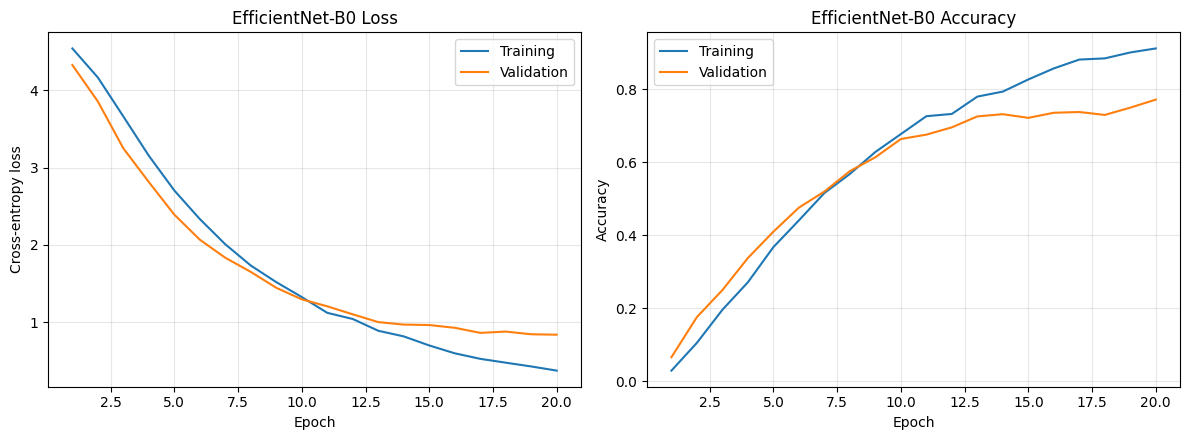

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].plot(history['epoch'], history['train_loss'], label='Training')
axes[0].plot(history['epoch'], history['val_loss'], label='Validation')
axes[0].set(title='EfficientNet-B0 Loss', xlabel='Epoch', ylabel='Cross-entropy loss')
axes[1].plot(history['epoch'], history['train_accuracy'], label='Training')
axes[1].plot(history['epoch'], history['val_accuracy'], label='Validation')
axes[1].set(title='EfficientNet-B0 Accuracy', xlabel='Epoch', ylabel='Accuracy')
for axis in axes:
    axis.legend()
    axis.grid(True, alpha=0.3)
fig.tight_layout()
fig.savefig(RESULTS_DIR / 'efficientnet_b0_training_curves.png', dpi=150)
plt.show()